In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Q1. Student Performance and Correlation Analysis

(a) Calculate correlation matrix and create heatmap

Correlation Matrix:
             Study_Hours  Attendance  Assignments  Sleep_Hours   Marks
Study_Hours       1.0000      0.9896       0.9768      -0.9685  0.9815
Attendance        0.9896      1.0000       0.9931      -0.9621  0.9930
Assignments       0.9768      0.9931       1.0000      -0.9525  0.9907
Sleep_Hours      -0.9685     -0.9621      -0.9525       1.0000 -0.9738
Marks             0.9815      0.9930       0.9907      -0.9738  1.0000


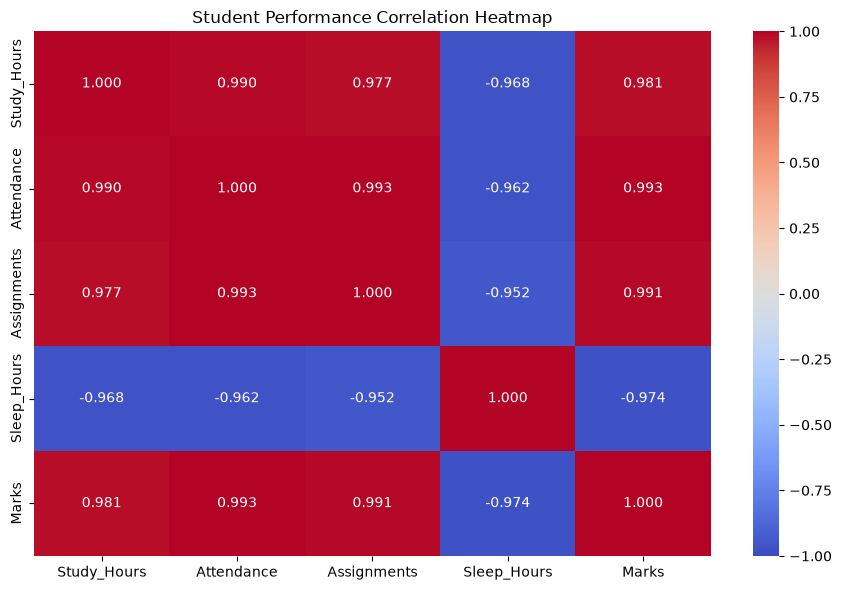


Feature Ranking by Absolute Correlation:
Attendance     0.993050
Assignments    0.990728
Study_Hours    0.981485
Sleep_Hours    0.973826
Name: Marks, dtype: float64

Actual Correlations with Marks:
Attendance     0.993050
Assignments    0.990728
Study_Hours    0.981485
Sleep_Hours   -0.973826
Name: Marks, dtype: float64


In [2]:
df = pd.DataFrame({"Study_Hours": [2, 3, 4, 5, 6, 7, 8, 9, 3, 6, 8, 4],
    "Attendance": [55, 60, 65, 70, 75, 80, 85, 95, 62, 78, 90, 68],
    "Assignments": [3, 4, 5, 5, 6, 7, 8, 10, 4, 7, 9, 5],
    "Sleep_Hours": [9, 8, 8, 7, 7, 6, 6, 5, 9, 7, 5, 8],
    "Marks": [40, 45, 50, 58, 65, 72, 78, 95, 43, 70, 90, 52]})

corr_matrix = df.corr(method="pearson")

print("Correlation Matrix:")
print(corr_matrix.round(4))

plt.figure(figsize=(9, 6))

sns.heatmap(corr_matrix,annot=True,cmap="coolwarm",fmt=".3f",vmin=-1,vmax=1)

plt.title("Student Performance Correlation Heatmap")
plt.tight_layout()
plt.show()

feature_corr = corr_matrix["Marks"].drop("Marks")

ranking = feature_corr.abs().sort_values(ascending=False)

print("\nFeature Ranking by Absolute Correlation:")
print(ranking.round(6))

print("\nActual Correlations with Marks:")
print(feature_corr.loc[ranking.index].round(6))


(b) Remove the student with the highest marks

Highest Marks: 95

Updated Correlation Matrix:
             Study_Hours  Attendance  Assignments  Sleep_Hours   Marks
Study_Hours       1.0000      0.9877       0.9732      -0.9591  0.9771
Attendance        0.9877      1.0000       0.9909      -0.9528  0.9901
Assignments       0.9732      0.9909       1.0000      -0.9432  0.9871
Sleep_Hours      -0.9591     -0.9528      -0.9432       1.0000 -0.9692
Marks             0.9771      0.9901       0.9871      -0.9692  1.0000

Correlation Comparison:
             Before_Removal  After_Removal    Change
Study_Hours        0.981485       0.977067 -0.004417
Attendance         0.993050       0.990149 -0.002901
Assignments        0.990728       0.987145 -0.003583
Sleep_Hours       -0.973826      -0.969244  0.004582


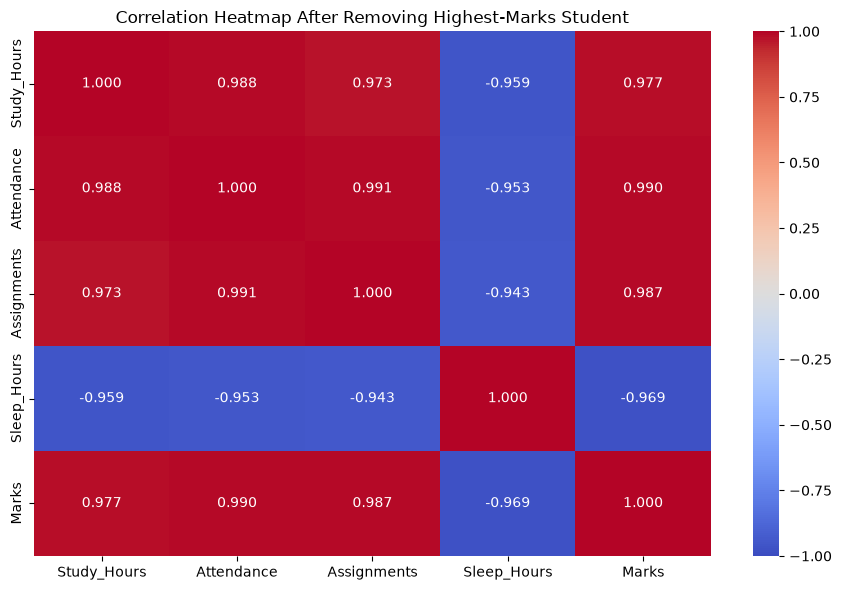

In [3]:
highest_index = df["Marks"].idxmax()

print("Highest Marks:", df.loc[highest_index, "Marks"])

df_new = df.drop(index=highest_index).copy()

new_corr = df_new.corr(method="pearson")

print("\nUpdated Correlation Matrix:")
print(new_corr.round(4))

comparison = pd.DataFrame({"Before_Removal": corr_matrix["Marks"],"After_Removal": new_corr["Marks"]})

comparison = comparison.drop("Marks")

comparison["Change"] = (comparison["After_Removal"]- comparison["Before_Removal"])

print("\nCorrelation Comparison:")
print(comparison.round(6))

plt.figure(figsize=(9, 6))

sns.heatmap(new_corr,annot=True,cmap="coolwarm",fmt=".3f",vmin=-1,vmax=1)

plt.title("Correlation Heatmap After Removing Highest-Marks Student")
plt.tight_layout()
plt.show()


Q2. Detecting Redundant Features in a Housing Dataset

(a) Correlation matrix, heatmap, and redundant feature pairs

Correlation Matrix:
             Area_sqft  Area_sqm  Bedrooms  Age_Years  Price_Lakhs
Area_sqft       1.0000    1.0000    0.9578    -0.9907       0.9992
Area_sqm        1.0000    1.0000    0.9578    -0.9907       0.9992
Bedrooms        0.9578    0.9578    1.0000    -0.9698       0.9548
Age_Years      -0.9907   -0.9907   -0.9698     1.0000      -0.9863
Price_Lakhs     0.9992    0.9992    0.9548    -0.9863       1.0000


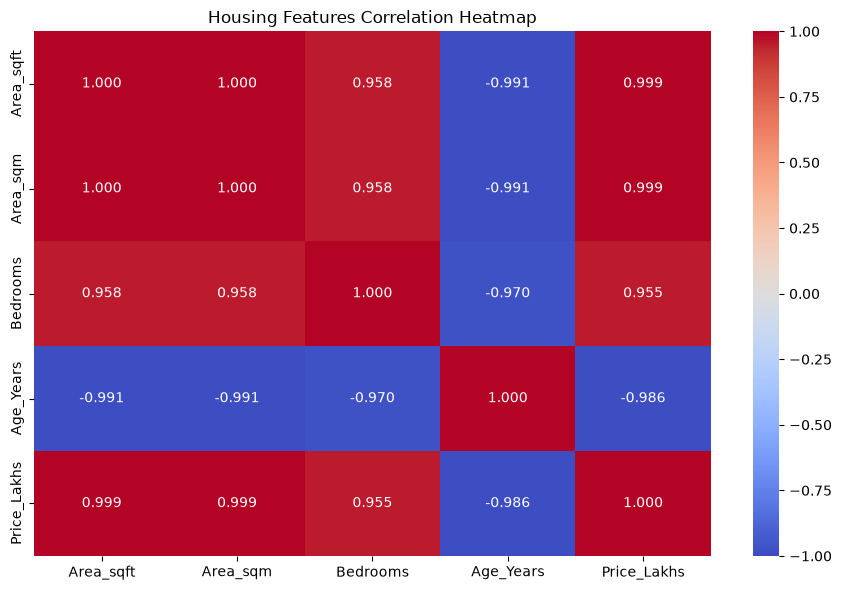


Highly Correlated Feature Pairs:
Area_sqft and Area_sqm : 1.0
Area_sqft and Bedrooms : 0.9578
Area_sqft and Age_Years : -0.9907
Area_sqft and Price_Lakhs : 0.9992
Area_sqm and Bedrooms : 0.9578
Area_sqm and Age_Years : -0.9907
Area_sqm and Price_Lakhs : 0.9992
Bedrooms and Age_Years : -0.9698
Bedrooms and Price_Lakhs : 0.9548
Age_Years and Price_Lakhs : -0.9863


In [4]:
df = pd.DataFrame({"Area_sqft": [800, 1000, 1200, 1400, 1600, 1800, 2000, 2200],
    "Area_sqm": [74.32, 92.90, 111.48, 130.06, 148.64, 167.22, 185.80, 204.38],
    "Bedrooms": [1, 2, 2, 3, 3, 3, 4, 4],
    "Age_Years": [25, 20, 18, 15, 12, 10, 8, 6],
    "Price_Lakhs": [25, 32, 38, 45, 52, 60, 68, 75]})

corr = df.corr(method="pearson")

print("Correlation Matrix:")
print(corr.round(4))

plt.figure(figsize=(9, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1
)
plt.title("Housing Features Correlation Heatmap")
plt.tight_layout()
plt.show()

threshold = 0.90
pairs = []

columns = corr.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        value = corr.iloc[i, j]

        if abs(value) > threshold:
            pairs.append(
                (columns[i], columns[j], value)
            )

print("\nHighly Correlated Feature Pairs:")
for feature1, feature2, value in pairs:
    print(feature1, "and", feature2, ":", round(value, 4))


(b) Compare two feature sets

Correlation Matrix - Both Area Features:
             Area_sqft  Area_sqm  Bedrooms  Age_Years  Price_Lakhs
Area_sqft       1.0000    1.0000    0.9578    -0.9907       0.9992
Area_sqm        1.0000    1.0000    0.9578    -0.9907       0.9992
Bedrooms        0.9578    0.9578    1.0000    -0.9698       0.9548
Age_Years      -0.9907   -0.9907   -0.9698     1.0000      -0.9863
Price_Lakhs     0.9992    0.9992    0.9548    -0.9863       1.0000

Correlation Matrix - Only Area_sqft:
             Area_sqft  Bedrooms  Age_Years  Price_Lakhs
Area_sqft       1.0000    0.9578    -0.9907       0.9992
Bedrooms        0.9578    1.0000    -0.9698       0.9548
Age_Years      -0.9907   -0.9698     1.0000      -0.9863
Price_Lakhs     0.9992    0.9548    -0.9863       1.0000

Correlation with Price (Both Area Features):
Area_sqft      0.9992
Area_sqm       0.9992
Bedrooms       0.9548
Age_Years     -0.9863
Price_Lakhs    1.0000
Name: Price_Lakhs, dtype: float64

Correlation with Price (Only Area_sqft):
Ar

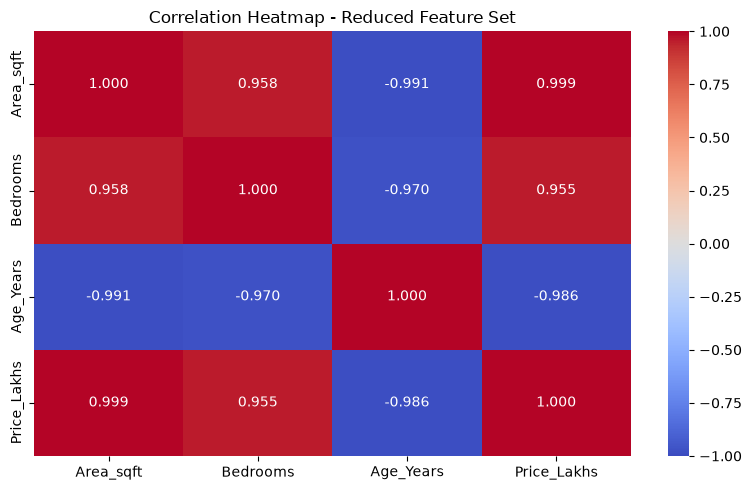

In [5]:

# Feature Set 1: Both area measurements
features_both = df[
    ["Area_sqft", "Area_sqm", "Bedrooms",
     "Age_Years", "Price_Lakhs"]
]

# Feature Set 2: Only Area_sqft
features_one = df[
    ["Area_sqft", "Bedrooms", "Age_Years",
     "Price_Lakhs"]
]

# Calculate correlation matrices
corr_both = features_both.corr()
corr_one = features_one.corr()

print("Correlation Matrix - Both Area Features:")
print(corr_both.round(4))

print("\nCorrelation Matrix - Only Area_sqft:")
print(corr_one.round(4))

# Compare each feature's correlation with price
print("\nCorrelation with Price (Both Area Features):")
print(corr_both["Price_Lakhs"].round(4))

print("\nCorrelation with Price (Only Area_sqft):")
print(corr_one["Price_Lakhs"].round(4))

# Heatmap for the reduced feature set
plt.figure(figsize=(8, 5))
sns.heatmap(
    corr_one,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Heatmap - Reduced Feature Set")
plt.tight_layout()
plt.show()


Q3. Customer Spending Analysis Using the Tips Dataset

(a) Calculate correlation matrix and create annotated heatmap

Correlation Matrix:
            total_bill     tip    size
total_bill      1.0000  0.6757  0.5983
tip             0.6757  1.0000  0.4893
size            0.5983  0.4893  1.0000


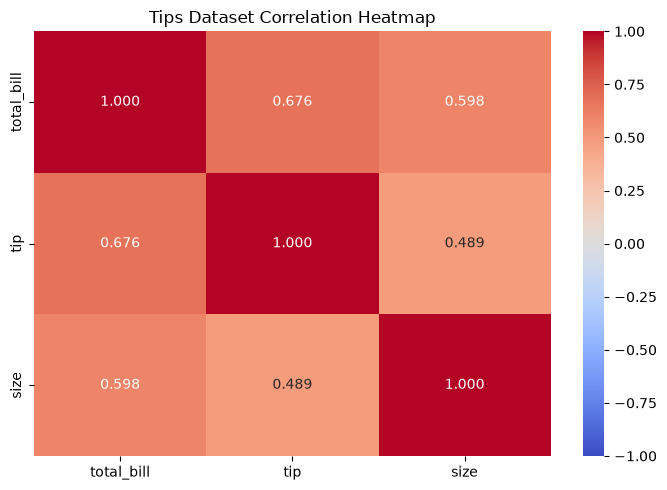

In [6]:
# Load built-in tips dataset
df = sns.load_dataset("tips")

# Select columns
data = df[["total_bill", "tip", "size"]]

# Calculate correlation matrix
corr = data.corr(method="pearson")

print("Correlation Matrix:")
print(corr.round(4))

# Create heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1
)

plt.title("Tips Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()


(b) Create tip_percentage and recalculate correlation

Updated Correlation Matrix:
                total_bill     tip    size  tip_percentage
total_bill          1.0000  0.6757  0.5983         -0.3386
tip                 0.6757  1.0000  0.4893          0.3424
size                0.5983  0.4893  1.0000         -0.1429
tip_percentage     -0.3386  0.3424 -0.1429          1.0000


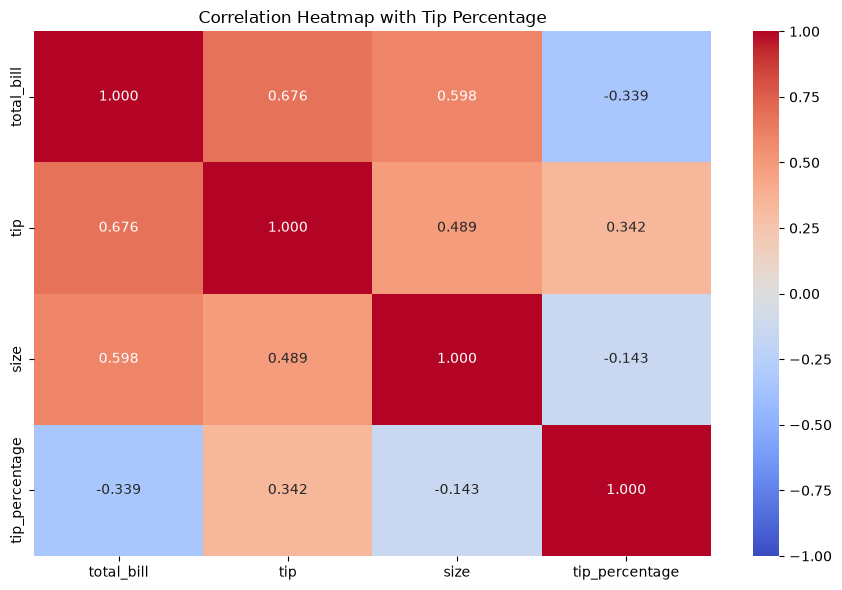


Tip Percentage Summary:
count    244.00
mean      16.08
std        6.11
min        3.56
25%       12.91
50%       15.48
75%       19.15
max       71.03
Name: tip_percentage, dtype: float64


In [7]:

# Create derived feature
df["tip_percentage"] = (
    df["tip"] / df["total_bill"]
) * 100

# Select all four columns
data_new = df[
    ["total_bill", "tip", "size", "tip_percentage"]
]

# Recalculate correlation matrix
corr_new = data_new.corr(method="pearson")

print("Updated Correlation Matrix:")
print(corr_new.round(4))

# Updated heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_new,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap with Tip Percentage")
plt.tight_layout()
plt.show()

# Display tip percentage summary
print("\nTip Percentage Summary:")
print(df["tip_percentage"].describe().round(2))


Q4. Investigating the Effect of an Outlier

(a) Calculate correlation matrix and plot heatmaps

Correlation Before Adding Outlier:
             Advertising     Sales
Advertising     1.000000  0.999868
Sales           0.999868  1.000000


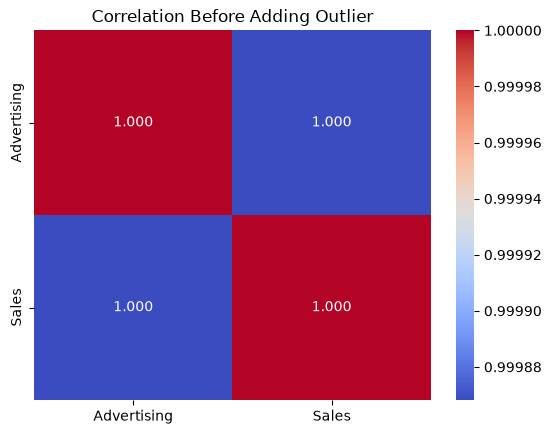


Correlation After Adding Outlier:
             Advertising     Sales
Advertising     1.000000  0.064683
Sales           0.064683  1.000000


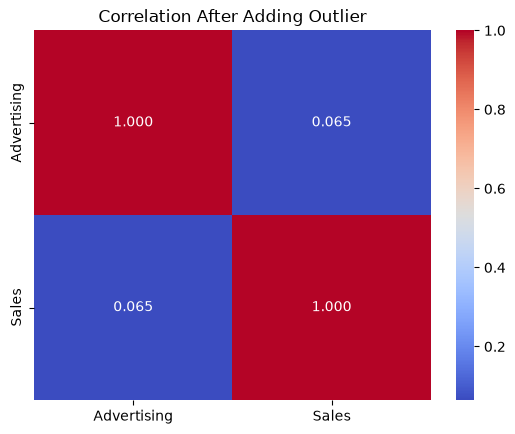


Correlation Before: 0.999868
Correlation After: 0.064683
Absolute Change: 0.935185
Percentage Decrease: 93.53 %


In [8]:


# Original DataFrame
df = pd.DataFrame({"Advertising": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55],
          "Sales": [20, 28, 35, 42, 50, 58, 65, 72, 80, 88]})

# Correlation before adding outlier
corr_before = df.corr()

print("Correlation Before Adding Outlier:")
print(corr_before.round(6))

# Heatmap before outlier
sns.heatmap(corr_before, annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Correlation Before Adding Outlier")
plt.show()

# Add unusual observation
new_row = pd.DataFrame({"Advertising": [100],"Sales": [10]})

df_new = pd.concat([df, new_row], ignore_index=True)

# Correlation after adding outlier
corr_after = df_new.corr()

print("\nCorrelation After Adding Outlier:")
print(corr_after.round(6))

# Heatmap after outlier
sns.heatmap(corr_after, annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Correlation After Adding Outlier")
plt.show()

# Calculate change
r1 = corr_before.loc["Advertising", "Sales"]
r2 = corr_after.loc["Advertising", "Sales"]

print("\nCorrelation Before:", round(r1, 6))
print("Correlation After:", round(r2, 6))
print("Absolute Change:", round(abs(r1 - r2), 6))

percentage_change = ((r1 - r2) / r1) * 100
print("Percentage Decrease:", round(percentage_change, 2), "%")

(b) Python code to flag potential outliers

In [9]:
# Detect potential outliers using IQR
for col in ["Advertising", "Sales"]:
    Q1 = df_new[col].quantile(0.25)
    Q3 = df_new[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_new[(df_new[col] < lower) |
        (df_new[col] > upper)]

    print("\nColumn:", col)
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Potential Outliers:")
    print(outliers)

# Compare correlation
print("\nBefore:", r1)
print("After:", r2)


Column: Advertising
Lower Bound: -15.0
Upper Bound: 85.0
Potential Outliers:
    Advertising  Sales
10          100     10

Column: Sales
Lower Bound: -24.0
Upper Bound: 124.0
Potential Outliers:
Empty DataFrame
Columns: [Advertising, Sales]
Index: []

Before: 0.9998682276680951
After: 0.06468331541572898
